# 06 · Churn Prediction

**คำถาม:** ครัวเรือนไหนกำลังจะ *หยุดหรือลดการซื้ออย่างมาก* ใน 8 สัปดาห์ข้างหน้า
เพื่อส่งโปรดึงกลับ **เฉพาะคนที่เสี่ยงจริง** — notebook 03 พบว่าป้าย At Risk ~83% กลับมาซื้อเอง

**นิยาม churn:** ยอดซื้อใน 8 สัปดาห์หลัง snapshot **น้อยกว่า 30%** ของยอดปกติ 8 สัปดาห์
(ยอดปกติ = ค่าเฉลี่ยจาก 26 สัปดาห์ก่อน snapshot) · หยุดซื้อทั้งหมดก็นับเป็น churn
เทียบกับค่าเฉลี่ยยาวแทนที่จะเทียบแค่ช่วงก่อนหน้า เพื่อลดผลของความผันผวนตามปกติ (บทเรียนจาก placebo test ใน notebook 04)

**กลุ่มที่ทำนาย:** ครัวเรือนที่มีประวัติครบ 26 สัปดาห์และยังซื้ออยู่ใน 8 สัปดาห์ก่อน snapshot (คนที่หายไปแล้วไม่ต้องทำนาย)

**ออกแบบเวลา (กันข้อมูลอนาคตรั่วเข้าโมเดล):**
```
feature: ข้อมูลถึงวัน snapshot เท่านั้น  │  label: 8 สัปดาห์ถัดไป
Train : snapshot สัปดาห์ 34, 42, 50, 58, 66, 74   (label จบก่อน snapshot ของ test)
Test  : snapshot สัปดาห์ 86 (out-of-time — โมเดลไม่เคยเห็นช่วงนี้)
Score : วันสุดท้ายของข้อมูล → รายชื่อลูกค้าเสี่ยงปัจจุบัน
```

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

from src.data import load, load_transactions_clean
from src.churn import (FEATURES, HORIZON_DAYS, snap_day_for_week, build_features, build_label,
                       at_risk_as_of, precision_at, recall_at)

tx = load_transactions_clean()
ct, cd = load("campaign_table"), load("campaign_desc")
seg = pd.read_parquet(config.PROCESSED_DIR / "segments.parquet")

TRAIN_WEEKS, TEST_WEEK, EXTRA_WEEK = [34, 42, 50, 58, 66, 74], 86, 93

def snapshot(week):
    d = snap_day_for_week(tx, week)
    f = build_features(tx, d, ct, cd)
    f["churn"] = build_label(tx, d, f)
    f["week"] = week
    return f

snaps = {w: snapshot(w) for w in TRAIN_WEEKS + [TEST_WEEK, EXTRA_WEEK]}
train = pd.concat([snaps[w] for w in TRAIN_WEEKS])
test = snaps[TEST_WEEK]

# ไม่มีข้อมูลอนาคตรั่ว: label ของชุด train จบก่อนวัน snapshot ของชุด test
assert train.snap_day.max() + HORIZON_DAYS <= test.snap_day.iloc[0]
for w, f in snaps.items():
    assert 0.10 <= f.churn.mean() <= 0.16, (w, f.churn.mean())

snap_tbl = pd.DataFrame({
    "snapshot day": {w: f.snap_day.iloc[0] for w, f in snaps.items()},
    "households": {w: len(f) for w, f in snaps.items()},
    "churn rate": {w: f.churn.mean() for w, f in snaps.items()},
    "ใช้เป็น": {w: "train" if w in TRAIN_WEEKS else ("test" if w == TEST_WEEK else "retrain สุดท้าย") for w in snaps},
}).rename_axis("snapshot week")
snap_tbl.to_parquet(config.PROCESSED_DIR / "churn_snapshots.parquet")
snap_tbl

,snapshot day,households,churn rate,ใช้เป็น
snapshot week,,,,
34,236,841,0.14,train
42,292,1982,0.14,train
50,348,2159,0.14,train
58,404,2180,0.13,train
66,460,2209,0.13,train
74,516,2221,0.15,train
86,600,2228,0.13,test
93,649,2226,0.13,retrain สุดท้าย


## 1. Feature (คำนวณจากข้อมูลถึงวัน snapshot เท่านั้น)
| กลุ่ม | ตัวแปร |
|---|---|
| ความถี่/ความใหม่ | `recency`, `median_gap` (ช่วงห่างปกติ), **`recency_ratio`** = recency ÷ ช่วงห่างปกติ |
| แนวโน้ม | `trend_spend`, `trend_baskets` = 8 สัปดาห์ล่าสุด ÷ ค่าปกติจาก 26 สัปดาห์, `weekly_cv` ความผันผวนรายสัปดาห์ |
| มูลค่า | `spend_8w`, `spend_26w`, `baskets_8w`, `baskets_26w`, `avg_basket` |
| ความผูกพัน | `n_commodities`, `n_stores`, `tenure_days` |
| โปรโมชัน | `promo_share`, `coupon_uses`, `campaigns_received`, `fuel_share` |

ไม่ใช้ข้อมูลประชากร เพราะมีแค่ 32% ของครัวเรือนและเอนเอียงไปทาง Champions

In [3]:
train.groupby("churn")[FEATURES].median().T.rename(columns={0: "ไม่ churn", 1: "churn"}).round(2)

churn,ไม่ churn,churn
recency,4.00,13.00
recency_ratio,0.67,1.14
median_gap,5.00,8.50
baskets_8w,8.00,3.00
baskets_26w,26.00,12.00
spend_8w,236.00,74.89
spend_26w,744.05,301.62
trend_spend,1.04,0.88
trend_baskets,1.04,0.95
weekly_cv,1.23,1.98


## 2. โมเดลเทียบกับ baseline (ชุด test สัปดาห์ 86)
- **Baseline 1 — ป้าย At Risk:** แบ่งกลุ่ม RFM + K-Means ใหม่ด้วยข้อมูลถึงวัน snapshot (วิธีเดียวกับ notebook 03) แล้วใช้ป้าย At Risk เป็นตัวทำนาย
- **Baseline 2 — recency:** ยิ่งไม่มานานยิ่งเสี่ยง
- **Logistic Regression** (log + standardize, อธิบายได้), **Random Forest**, **HistGradientBoosting**

เกณฑ์หลักคือ **PR-AUC** (เหมาะกับข้อมูลที่ churn มีน้อย) และ **precision ใน top 10%**
= "ถ้าส่งโปรให้ 10% ที่เสี่ยงสุด จะโดนคนที่ churn จริงกี่ %"

In [4]:
X, y, Xt, yt = train[FEATURES], train.churn, test[FEATURES], test.churn
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)))

models = {
    "Logistic Regression": make_pipeline(signed_log, StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(400, min_samples_leaf=20, n_jobs=-1, random_state=config.RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, min_samples_leaf=40,
                                                           random_state=config.RANDOM_STATE),
}
seg_test = at_risk_as_of(tx, test.snap_day.iloc[0]).reindex(test.index)
scores = {
    "Baseline: ป้าย At Risk": (seg_test == "At Risk").astype(float).to_numpy(),
    "Baseline: recency": test.recency.to_numpy(),
}
for name, m in models.items():
    m.fit(X, y)
    scores[name] = m.predict_proba(Xt)[:, 1]

ev = pd.DataFrame({n: {
    "ROC-AUC": roc_auc_score(yt, s),
    "PR-AUC": average_precision_score(yt, s),
    "precision top 10%": precision_at(yt, s, 0.10),
    "recall top 10%": recall_at(yt, s, 0.10),
} for n, s in scores.items()}).T
ev.loc["Baseline: ป้าย At Risk", ["precision top 10%", "recall top 10%"]] = np.nan  # ป้ายเป็น 0/1 จัดอันดับ top 10% ไม่ได้
base_rate = yt.mean()
print(f"churn rate ในชุด test = {base_rate:.1%} (ส่งแบบสุ่มจะโดนคน churn {base_rate:.0%})")
ev.round(3)

churn rate ในชุด test = 13.1% (ส่งแบบสุ่มจะโดนคน churn 13%)


,ROC-AUC,PR-AUC,precision top 10%,recall top 10%
Baseline: ป้าย At Risk,0.64,0.19,NaN,NaN
Baseline: recency,0.72,0.27,0.34,0.27
Logistic Regression,0.79,0.32,0.37,0.28
Random Forest,0.78,0.31,0.34,0.26
HistGradientBoosting,0.77,0.32,0.34,0.26


### เทียบแบบงบเท่ากัน: ส่งโปรให้กลุ่ม At Risk ทั้งกลุ่ม vs ส่งให้คนที่โมเดลให้คะแนนสูงสุดจำนวนเท่ากัน

In [5]:
BEST = "Logistic Regression"
is_risk = (seg_test == "At Risk").to_numpy()
share = is_risk.mean()
budget = pd.DataFrame({
    "ส่งให้ (ครัวเรือน)": [is_risk.sum()] * 3,
    "precision (โดนคน churn)": [yt[is_risk].mean(), precision_at(yt, scores["Baseline: recency"], share),
                                 precision_at(yt, scores[BEST], share)],
    "recall (จับคน churn ได้)": [yt[is_risk].sum() / yt.sum(), recall_at(yt, scores["Baseline: recency"], share),
                                 recall_at(yt, scores[BEST], share)],
}, index=["ป้าย At Risk ทั้งกลุ่ม", "recency สูงสุด", f"{BEST} สูงสุด"])
print(f"At Risk = {share:.0%} ของครัวเรือนที่ทำนายในชุด test")
budget.round(3)

At Risk = 26% ของครัวเรือนที่ทำนายในชุด test


,ส่งให้ (ครัวเรือน),precision (โดนคน churn),recall (จับคน churn ได้)
ป้าย At Risk ทั้งกลุ่ม,578,0.25,0.51
recency สูงสุด,578,0.27,0.54
Logistic Regression สูงสุด,578,0.30,0.60


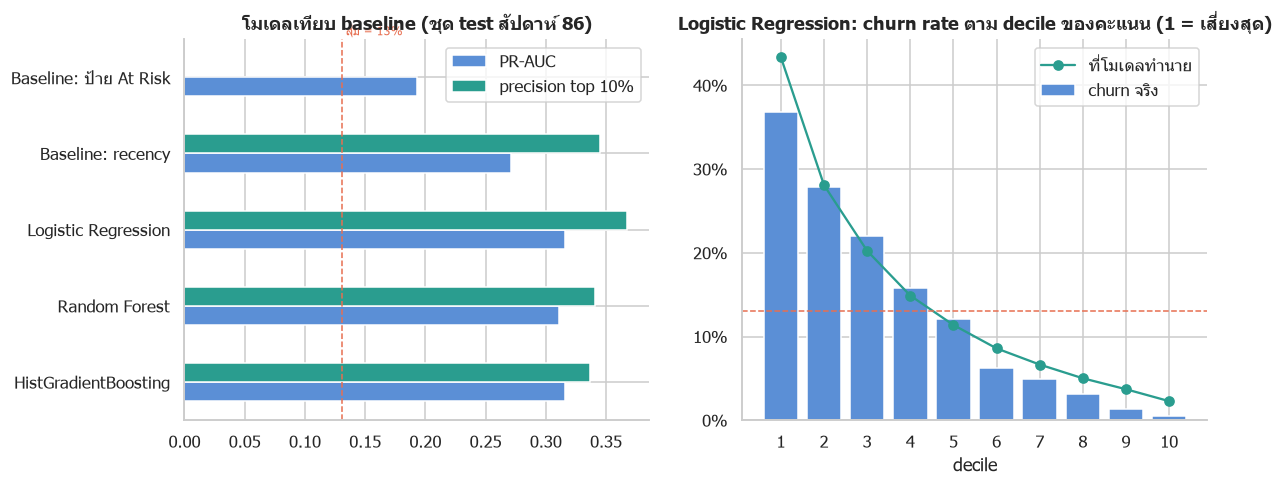

,predicted,actual
decile,,
1,0.43,0.37
2,0.28,0.28
3,0.20,0.22
4,0.15,0.16
5,0.11,0.12
6,0.09,0.06
7,0.07,0.05
8,0.05,0.03
9,0.04,0.01


In [6]:
best = scores[BEST]
dec = pd.qcut(pd.Series(best).rank(method="first", ascending=False), 10, labels=range(1, 11))
by_dec = pd.DataFrame({"predicted": best, "actual": yt.to_numpy(), "decile": dec}).groupby("decile", observed=True).mean()
by_dec = by_dec.sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_ev = ev[["PR-AUC", "precision top 10%"]].iloc[::-1]
plot_ev.plot.barh(ax=axes[0], color=[PRIMARY, ACCENT])
axes[0].axvline(base_rate, color="#e76f51", ls="--", lw=1)
axes[0].text(base_rate, len(plot_ev) - 0.45, f" สุ่ม = {base_rate:.0%}", color="#e76f51", fontsize=8)
axes[0].set_title("โมเดลเทียบ baseline (ชุด test สัปดาห์ 86)")
axes[0].set_xlabel("")
axes[1].bar(by_dec.index.astype(str), by_dec.actual, color=PRIMARY, label="churn จริง")
axes[1].plot(by_dec.index.astype(str), by_dec.predicted, "o-", color=ACCENT, label="ที่โมเดลทำนาย")
axes[1].axhline(base_rate, color="#e76f51", ls="--", lw=1)
axes[1].set_title(f"{BEST}: churn rate ตาม decile ของคะแนน (1 = เสี่ยงสุด)")
axes[1].set_xlabel("decile")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
save(fig, "06_model_compare")
plt.show()
by_dec.round(3)

### 2.1 ทดสอบซ้ำที่ snapshot สัปดาห์ 93 + ช่วงความเชื่อมั่น
ผลจากสัปดาห์ทดสอบเดียวอาจดีหรือแย่เกินจริง จึงทดสอบที่สัปดาห์ 93 ด้วย (label จบวันที่ 705 ยังอยู่ในข้อมูล · โมเดลยังฝึกด้วยสัปดาห์ 34–74 เท่าเดิม)
และ bootstrap ครัวเรือน 500 รอบเพื่อดูว่า *ผลต่างระหว่างโมเดลกับ baseline* ต่างจากศูนย์จริงหรือไม่

นอกจากความแม่น ยังวัด **ผลที่เกิดขึ้นจริง** ของการเลือกคนด้วยงบเท่ากัน (จำนวนครัวเรือนเท่ากับกลุ่ม At Risk):
ยอดที่หายไปจริงของคนที่ churn (ยอดปกติ 8 สัปดาห์ − ยอดที่ซื้อจริง) ถูกครอบคลุมกี่ %
- **A:** ป้าย At Risk ทั้งกลุ่ม · **B:** โอกาส churn สูงสุด · **C:** โอกาส churn × ยอดซื้อปกติ สูงสุด · **D:** ยอดซื้อสูงสุดอย่างเดียว

In [7]:
def eval_week(week):
    f = snaps[week]
    seg_w = at_risk_as_of(tx, f.snap_day.iloc[0]).reindex(f.index)
    s = {n: m.predict_proba(f[FEATURES])[:, 1] for n, m in models.items()}
    s["recency"] = f.recency.to_numpy()
    return f, f.churn.to_numpy(), (seg_w == "At Risk").to_numpy(), s

rng = np.random.default_rng(config.RANDOM_STATE)
ev_rows, bud_rows, diff_rows, cov_rows, cal_rows = [], [], [], [], []
for week in [TEST_WEEK, EXTRA_WEEK]:
    f, y, ar, s = eval_week(week)
    d, n, share = int(f.snap_day.iloc[0]), int(ar.sum()), ar.mean()
    lr, rec = s[BEST], s["recency"]

    for name, sc in [(BEST, lr), ("Random Forest", s["Random Forest"]), ("HistGradientBoosting", s["HistGradientBoosting"]),
                     ("Baseline: recency", rec), ("Baseline: ป้าย At Risk", ar.astype(float))]:
        ev_rows.append({"test week": week, "model": name, "ROC-AUC": roc_auc_score(y, sc),
                        "PR-AUC": average_precision_score(y, sc),
                        "precision top 10%": np.nan if name.endswith("At Risk") else precision_at(y, sc, 0.10)})
    for name, p, r in [("ป้าย At Risk ทั้งกลุ่ม", y[ar].mean(), y[ar].sum() / y.sum()),
                       ("recency สูงสุด", precision_at(y, rec, share), recall_at(y, rec, share)),
                       (BEST + " สูงสุด", precision_at(y, lr, share), recall_at(y, lr, share))]:
        bud_rows.append({"test week": week, "pick": name, "households": n, "precision": p, "recall": r})

    stats = {"PR-AUC: LR - recency": [], "precision top 10%: LR - recency": [],
             "precision งบเท่ากัน: LR - ป้าย At Risk": [], "precision งบเท่ากัน: LR - recency": []}
    for _ in range(500):
        i = rng.integers(0, len(y), len(y))
        yy, a, r, b = y[i], lr[i], rec[i], ar[i]
        sh = b.mean()
        stats["PR-AUC: LR - recency"].append(average_precision_score(yy, a) - average_precision_score(yy, r))
        stats["precision top 10%: LR - recency"].append(precision_at(yy, a, 0.10) - precision_at(yy, r, 0.10))
        stats["precision งบเท่ากัน: LR - ป้าย At Risk"].append(precision_at(yy, a, sh) - yy[b].mean())
        stats["precision งบเท่ากัน: LR - recency"].append(precision_at(yy, a, sh) - precision_at(yy, r, sh))
    point = {"PR-AUC: LR - recency": average_precision_score(y, lr) - average_precision_score(y, rec),
             "precision top 10%: LR - recency": precision_at(y, lr, 0.10) - precision_at(y, rec, 0.10),
             "precision งบเท่ากัน: LR - ป้าย At Risk": precision_at(y, lr, share) - y[ar].mean(),
             "precision งบเท่ากัน: LR - recency": precision_at(y, lr, share) - precision_at(y, rec, share)}
    for k, v in stats.items():
        lo, hi = np.percentile(v, [2.5, 97.5])
        diff_rows.append({"test week": week, "measure": k, "diff": point[k], "ci_low": lo, "ci_high": hi, "significant": bool(lo > 0)})

    usual8 = f.spend_26w * 8 / 26
    nxt = tx[(tx.DAY > d) & (tx.DAY <= d + HORIZON_DAYS)].groupby("household_key").SALES_VALUE.sum().reindex(f.index, fill_value=0)
    lost = ((usual8 - nxt) * f.churn).clip(lower=0)
    lr_s = pd.Series(lr, f.index)
    picks = {"A: ป้าย At Risk ทั้งกลุ่ม": f.index[ar],
             "B: โอกาส churn สูงสุด": lr_s.nlargest(n).index,
             "C: โอกาส churn x ยอดซื้อ สูงสุด": (lr_s * f.spend_26w).nlargest(n).index,
             "D: ยอดซื้อสูงสุดอย่างเดียว": f.spend_26w.nlargest(n).index}
    for k, idx in picks.items():
        cov_rows.append({"test week": week, "pick": k, "households": n, "churners reached": int(f.churn[idx].sum()),
                         "% of all churners": f.churn[idx].sum() / f.churn.sum() * 100,
                         "% of lost spend": lost[idx].sum() / lost.sum() * 100})
    cal_rows.append({"test week": week, "actual rate": y.mean(), "mean predicted": lr.mean(), "factor": y.mean() / lr.mean()})

ev_all, bud_all = pd.DataFrame(ev_rows), pd.DataFrame(bud_rows)
diffs, cov, cal = pd.DataFrame(diff_rows), pd.DataFrame(cov_rows), pd.DataFrame(cal_rows)
CALIB = float(cal["factor"].mean())

print("โมเดลเทียบ baseline ที่ 2 สัปดาห์ทดสอบ")
display(ev_all.set_index(["test week", "model"]).round(3))
print("งบเท่ากับกลุ่ม At Risk")
display(bud_all.set_index(["test week", "pick"]).round(3))
print("ผลต่าง LR - baseline (bootstrap 95% CI) — significant = ช่วงไม่คร่อม 0")
display(diffs.set_index(["test week", "measure"]).round(3))
print("ผลที่เกิดขึ้นจริงของการเลือกคนด้วยงบเท่ากัน")
display(cov.set_index(["test week", "pick"]).round(1))
print(f"คะแนนที่โมเดลให้สูงกว่าอัตรา churn จริง: factor = จริง/ทำนาย = {cal['factor'].round(3).tolist()} → ใช้ {CALIB:.2f} ปรับยอดรวม")

โมเดลเทียบ baseline ที่ 2 สัปดาห์ทดสอบ


ROC-AUC  PR-AUC  precision top 10%
test week model                                                     
86        Logistic Regression        0.79    0.32               0.37
          Random Forest              0.78    0.31               0.34
          HistGradientBoosting       0.77    0.32               0.34
          Baseline: recency          0.72    0.27               0.34
          Baseline: ป้าย At Risk     0.64    0.19                NaN
93        Logistic Regression        0.75    0.30               0.36
          Random Forest              0.76    0.31               0.38
          HistGradientBoosting       0.75    0.31               0.35
          Baseline: recency          0.68    0.25               0.32
          Baseline: ป้าย At Risk     0.55    0.15                NaN

งบเท่ากับกลุ่ม At Risk


households  precision  recall
test week pick                                                     
86        ป้าย At Risk ทั้งกลุ่ม             578       0.25    0.51
          recency สูงสุด                     578       0.27    0.54
          Logistic Regression สูงสุด         578       0.30    0.60
93        ป้าย At Risk ทั้งกลุ่ม             475       0.18    0.30
          recency สูงสุด                     475       0.27    0.43
          Logistic Regression สูงสุด         475       0.30    0.48

ผลต่าง LR - baseline (bootstrap 95% CI) — significant = ช่วงไม่คร่อม 0


diff  ci_low  ci_high  significant
test week measure                                                                   
86        PR-AUC: LR - recency                    0.04    0.01     0.08         True
          precision top 10%: LR - recency         0.02   -0.03     0.09        False
          precision งบเท่ากัน: LR - ป้าย At Risk  0.05    0.02     0.08         True
          precision งบเท่ากัน: LR - recency       0.03    0.01     0.06         True
93        PR-AUC: LR - recency                    0.04    0.01     0.08         True
          precision top 10%: LR - recency         0.04   -0.02     0.09        False
          precision งบเท่ากัน: LR - ป้าย At Risk  0.12    0.08     0.16         True
          precision งบเท่ากัน: LR - recency       0.03    0.00     0.07         True

ผลที่เกิดขึ้นจริงของการเลือกคนด้วยงบเท่ากัน


households  churners reached  % of all churners  % of lost spend
test week pick                                                                                             
86        A: ป้าย At Risk ทั้งกลุ่ม               578               147              50.50            27.20
          B: โอกาส churn สูงสุด                   578               174              59.80            37.00
          C: โอกาส churn x ยอดซื้อ สูงสุด         578                99              34.00            64.20
          D: ยอดซื้อสูงสุดอย่างเดียว              578                23               7.90            31.30
93        A: ป้าย At Risk ทั้งกลุ่ม               475                87              29.60            25.70
          B: โอกาส churn สูงสุด                   475               142              48.30            24.80
          C: โอกาส churn x ยอดซื้อ สูงสุด         475                79              26.90            50.10
          D: ยอดซื้อสูงสุดอย่างเดียว              475                20               6.80            28.00

คะแนนที่โมเดลให้สูงกว่าอัตรา churn จริง: factor = จริง/ทำนาย = [0.906, 0.923] → ใช้ 0.91 ปรับยอดรวม


## 3. อะไรทำนาย churn ได้ดี (grouped permutation importance บนชุด test สัปดาห์ 86)
ตัวแปรหลายตัวสัมพันธ์กันสูง (เช่น จำนวนตะกร้า 8 และ 26 สัปดาห์ หรือ recency กับ recency_ratio) การสลับค่าทีละตัวจะประเมินความสำคัญต่ำเกินจริง
และสัมประสิทธิ์รายตัวก็ตีความทิศทางไม่ได้ จึงสลับ **ทั้งกลุ่มตัวแปรพร้อมกัน** (20 รอบ) แล้ววัด PR-AUC ที่ลดลง

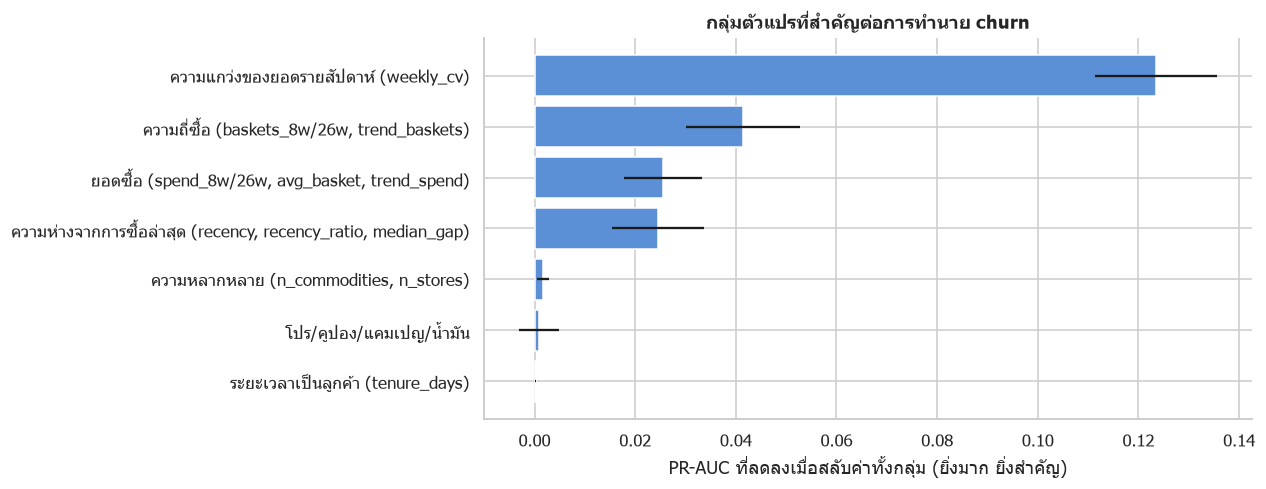

,PR-AUC ที่ลดลง,std
ความแกว่งของยอดรายสัปดาห์ (weekly_cv),0.12,0.01
"ความถี่ซื้อ (baskets_8w/26w, trend_baskets)",0.04,0.01
"ยอดซื้อ (spend_8w/26w, avg_basket, trend_spend)",0.03,0.01
"ความห่างจากการซื้อล่าสุด (recency, recency_ratio, median_gap)",0.03,0.01
"ความหลากหลาย (n_commodities, n_stores)",0.00,0.00
โปร/คูปอง/แคมเปญ/น้ำมัน,0.00,0.00
ระยะเวลาเป็นลูกค้า (tenure_days),0.00,0.00


In [8]:
GROUPS = {
    "ความถี่ซื้อ (baskets_8w/26w, trend_baskets)": ["baskets_8w", "baskets_26w", "trend_baskets"],
    "ความแกว่งของยอดรายสัปดาห์ (weekly_cv)": ["weekly_cv"],
    "ความห่างจากการซื้อล่าสุด (recency, recency_ratio, median_gap)": ["recency", "recency_ratio", "median_gap"],
    "ยอดซื้อ (spend_8w/26w, avg_basket, trend_spend)": ["spend_8w", "spend_26w", "avg_basket", "trend_spend"],
    "ความหลากหลาย (n_commodities, n_stores)": ["n_commodities", "n_stores"],
    "โปร/คูปอง/แคมเปญ/น้ำมัน": ["promo_share", "coupon_uses", "campaigns_received", "fuel_share"],
    "ระยะเวลาเป็นลูกค้า (tenure_days)": ["tenure_days"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)

base_pr = average_precision_score(yt, models[BEST].predict_proba(Xt)[:, 1])
rng = np.random.default_rng(config.RANDOM_STATE)
rows = {}
for g, cols in GROUPS.items():
    drops = []
    for _ in range(20):
        Xp = Xt.copy()
        Xp[cols] = Xt[cols].iloc[rng.permutation(len(Xt))].to_numpy()
        drops.append(base_pr - average_precision_score(yt, models[BEST].predict_proba(Xp)[:, 1]))
    rows[g] = (np.mean(drops), np.std(drops))
imp = pd.DataFrame(rows, index=["PR-AUC ที่ลดลง", "std"]).T.sort_values("PR-AUC ที่ลดลง")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp["PR-AUC ที่ลดลง"], xerr=imp["std"], color=PRIMARY)
ax.set_title("กลุ่มตัวแปรที่สำคัญต่อการทำนาย churn")
ax.set_xlabel("PR-AUC ที่ลดลงเมื่อสลับค่าทั้งกลุ่ม (ยิ่งมาก ยิ่งสำคัญ)")
save(fig, "06_importance")
plt.show()
imp.iloc[::-1].round(3)

In [9]:
single = {"recency (ยิ่งนานยิ่งเสี่ยง)": Xt["recency"], "baskets_8w (ยิ่งน้อยยิ่งเสี่ยง)": -Xt["baskets_8w"],
          "weekly_cv (ยิ่งแกว่งยิ่งเสี่ยง)": Xt["weekly_cv"]}
print("PR-AUC ของตัวแปรเดี่ยว (ชุด test):", {k: round(average_precision_score(yt, v), 3) for k, v in single.items()}, f"· สุ่ม = {base_rate:.3f}")

PR-AUC ของตัวแปรเดี่ยว (ชุด test): {'recency (ยิ่งนานยิ่งเสี่ยง)': 0.271, 'baskets_8w (ยิ่งน้อยยิ่งเสี่ยง)': 0.265, 'weekly_cv (ยิ่งแกว่งยิ่งเสี่ยง)': 0.284} · สุ่ม = 0.131


## 4. คะแนนความเสี่ยง ณ วันสุดท้ายของข้อมูล
ฝึก Logistic Regression ใหม่ด้วยทุก snapshot ที่มี label (สัปดาห์ 34–93) แล้วให้คะแนนครัวเรือนที่ยังซื้ออยู่ ณ วันสุดท้าย

In [10]:
final_model = make_pipeline(signed_log, StandardScaler(), LogisticRegression(max_iter=2000))
all_lab = pd.concat(snaps.values())
final_model.fit(all_lab[FEATURES], all_lab.churn)

last_day = int(tx.DAY.max())
now = build_features(tx, last_day, ct, cd)
now["churn_score"] = final_model.predict_proba(now[FEATURES])[:, 1]
now["churn_score_adj"] = (now.churn_score * CALIB).clip(upper=1)   # ปรับให้ตรงกับอัตรา churn จริงที่ชุด test (โมเดลให้คะแนนสูงไปเล็กน้อย)
now["risk_decile"] = pd.qcut(now.churn_score.rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
now["segment"] = now.index.map(seg.segment)
now["weekly_usual_spend"] = now.spend_26w / 26
churn_scores = now[["churn_score", "churn_score_adj", "risk_decile", "segment", "weekly_usual_spend", "recency", "recency_ratio", "trend_spend"]]
churn_scores.to_parquet(config.PROCESSED_DIR / "churn_scores.parquet")

not_scored = seg.index.difference(now.index)
print(f"ให้คะแนน {len(now):,} ครัวเรือน · ไม่ได้ให้คะแนน {len(not_scored):,} (หายไปเกิน 8 สัปดาห์แล้ว หรือประวัติไม่ถึง 26 สัปดาห์)")
print(f"คาดว่าจะ churn ใน 8 สัปดาห์ข้างหน้า ≈ {now.churn_score_adj.sum():.0f} ครัวเรือน ({now.churn_score_adj.mean():.0%}) · ก่อนปรับ {now.churn_score.sum():.0f}")

risk_seg = now.groupby("segment").agg(
    households=("churn_score", "size"),
    mean_score=("churn_score", "mean"),
    in_top_decile=("risk_decile", lambda d: (d == 1).sum()),
).reindex(config.SEGMENT_ORDER)
risk_seg["% of top decile"] = risk_seg.in_top_decile / risk_seg.in_top_decile.sum() * 100
risk_seg["not scored (already lapsed / new)"] = seg.loc[not_scored, "segment"].value_counts().reindex(config.SEGMENT_ORDER).fillna(0).astype(int)
risk_seg.round(2)

ให้คะแนน 2,214 ครัวเรือน · ไม่ได้ให้คะแนน 286 (หายไปเกิน 8 สัปดาห์แล้ว หรือประวัติไม่ถึง 26 สัปดาห์)
คาดว่าจะ churn ใน 8 สัปดาห์ข้างหน้า ≈ 275 ครัวเรือน (12%) · ก่อนปรับ 301


,households,mean_score,in_top_decile,% of top decile,not scored (already lapsed / new)
segment,,,,,
Champions,916,0.06,6,2.70,0
Loyal,647,0.13,21,9.46,0
At Risk,469,0.23,98,44.14,106
Occasional,182,0.32,97,43.69,180


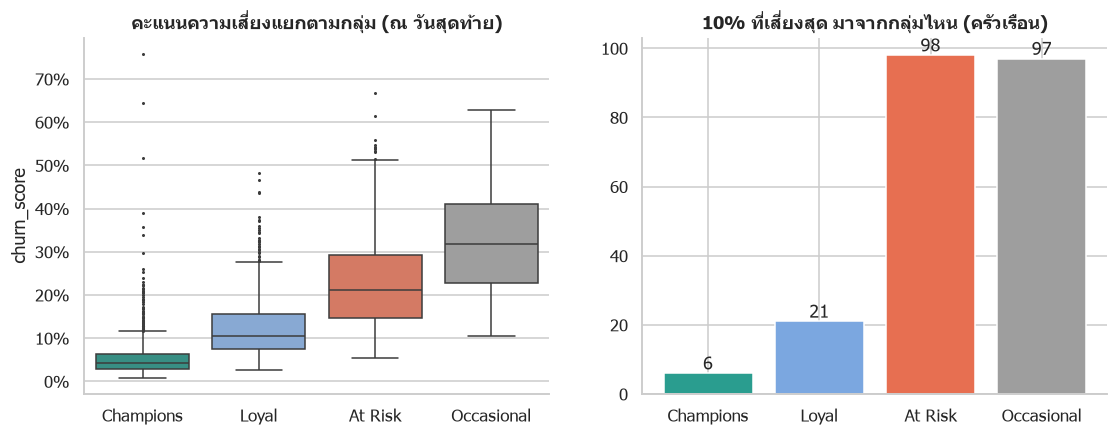

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=now, x="segment", y="churn_score", order=config.SEGMENT_ORDER, palette=seg_palette(), ax=axes[0], fliersize=1)
axes[0].set_title("คะแนนความเสี่ยงแยกตามกลุ่ม (ณ วันสุดท้าย)")
axes[0].set_xlabel("")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].bar(risk_seg.index, risk_seg.in_top_decile, color=seg_palette())
axes[1].set_title("10% ที่เสี่ยงสุด มาจากกลุ่มไหน (ครัวเรือน)")
for i, v in enumerate(risk_seg.in_top_decile):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")
save(fig, "06_risk_by_segment")
plt.show()

In [12]:
ev_all.to_parquet(config.PROCESSED_DIR / "churn_model_eval.parquet")
bud_all.to_parquet(config.PROCESSED_DIR / "churn_budget_compare.parquet")
diffs.to_parquet(config.PROCESSED_DIR / "churn_diffs.parquet")
cov.to_parquet(config.PROCESSED_DIR / "churn_coverage.parquet")
cal.to_parquet(config.PROCESSED_DIR / "churn_calibration.parquet")
print("saved churn_scores / churn_model_eval / churn_budget_compare / churn_diffs / churn_coverage / churn_calibration / churn_snapshots")

saved churn_scores / churn_model_eval / churn_budget_compare / churn_diffs / churn_coverage / churn_calibration / churn_snapshots


## สรุป Churn Prediction

ทดสอบแบบ out-of-time 2 สัปดาห์ (snapshot สัปดาห์ 86 และ 93) · โมเดลฝึกด้วยสัปดาห์ 34–74 เท่านั้น

| ผล | สัปดาห์ทดสอบ 86 | สัปดาห์ทดสอบ 93 |
|---|---|---|
| churn rate จริง | 13.1% | 13.2% |
| ROC-AUC (LR / recency / ป้าย At Risk) | 0.79 / 0.72 / 0.64 | 0.75 / 0.68 / 0.55 |
| PR-AUC (LR / recency / ป้าย At Risk) | 0.32 / 0.27 / 0.19 | 0.30 / 0.25 / 0.15 |
| precision ใน top 10% (LR / recency) | 37% / 35% | 36% / 32% |
| งบเท่ากับกลุ่ม At Risk — precision (At Risk / recency / LR) | 25% / 27% / 30% | 18% / 27% / 30% |
| ยอดที่หายไปจริงของคน churn ที่ครอบคลุม (A ป้าย At Risk / D ยอดซื้อสูงสุด / C โอกาส × ยอดซื้อ) | 27% / 31% / **64%** | 26% / 28% / **50%** |

**ข้อค้นพบ**
1. **โมเดลดีกว่าป้าย At Risk ชัดเจน แต่ดีกว่า recency แบบง่ายเพียงเล็กน้อย** — งบเท่ากันแม่นกว่าป้าย At Risk +5 ถึง +12 จุด (CI ไม่คร่อม 0 ทั้งสองสัปดาห์)
   แต่เทียบ recency อย่างเดียวได้เพิ่ม ~+3 จุด (CI แคบมาก: 0.5–5.7 และ 0.1–6.6) และ precision ใน top 10% **ไม่ต่างอย่างมีนัยสำคัญ** (CI คร่อม 0)
2. **Logistic Regression, Random Forest, HistGradientBoosting ให้ผลใกล้เคียงกัน** (PR-AUC 0.30–0.32) ไม่มีตัวใดชนะสม่ำเสมอ · เลือก Logistic Regression เพราะอธิบายได้
3. **ตัวแปรที่ช่วยทำนาย:** ความแกว่งของยอดรายสัปดาห์ (weekly_cv) สำคัญที่สุด · ความถี่ซื้อ, ยอดซื้อ และความห่างจากการซื้อล่าสุด (recency) สำคัญรองลงมาในระดับใกล้กัน ·
   โปร คูปอง แคมเปญ น้ำมัน และอายุลูกค้าแทบไม่ช่วย · ตัวแปรเดี่ยวอย่าง weekly_cv หรือ recency ก็ได้ PR-AUC 0.27–0.28 โมเดลรวมทุกตัวเพิ่มเป็น 0.32
4. **ส่วนที่เพิ่มคุณค่าจริงคือการเลือกตามยอดซื้อ ไม่ใช่ความแม่นของโมเดล** — งบเท่ากัน วิธี C (โอกาส churn × ยอดซื้อ) ครอบคลุมยอดที่หายไปจริง 50–64% เทียบ 26–27% ของป้าย At Risk
   ส่วนวิธี B (โอกาส churn สูงสุดอย่างเดียว) จับคน churn ได้มากที่สุด แต่เป็นคนยอดต่ำ จึงครอบคลุมยอดที่หายไปได้แค่ 25–37%
5. **คะแนนสูงกว่าอัตราจริงราว 8–9%** (เฉลี่ย 14.4% เทียบจริง 13.1%) ผลของการทดสอบข้ามเวลา · การจัดอันดับไม่เปลี่ยน แต่ตัวเลขรวมต้องปรับลด (ใช้ factor 0.91 ใน `churn_score_adj`)
6. **ณ วันสุดท้าย:** ให้คะแนน 2,214 ครัวเรือน คาดว่าจะ churn ~275 (12%) ใน 8 สัปดาห์ข้างหน้า (ก่อนปรับ 301) ·
   10% ที่เสี่ยงสุด (222 ครัวเรือน) มาจาก At Risk 44% · Occasional 44% · **Loyal/Champions 12% ที่ป้าย At Risk มองไม่เห็น**
7. **286 ครัวเรือนหายไปเกิน 8 สัปดาห์แล้ว** (At Risk 106, Occasional 180) — ไม่ต้องทำนาย ใช้แคมเปญ reactivation ต้นทุนต่ำแยกต่างหาก

**ข้อจำกัด:** churn เป็นแบบลดยอดมาก ไม่ใช่ปิดบัญชี (ไม่มีข้อมูลนั้น) · บางคนอาจไปซื้อสาขาอื่นของคู่แข่งชั่วคราว ·
โมเดลบอกว่า *ใครเสี่ยง* ไม่ได้บอกว่า *โปรดึงกลับได้ผล* → ต้องทดสอบเทียบ holdout